In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics", version = "6.36.0", force = TRUE)
}

library(mixOmics)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




In [23]:
DATA_DIR <- "/home/mariya/Data/pallas/mixOmics/models_20260809"
GEX_FILE <- file.path(DATA_DIR, "perf.gex.rds")
DNAM_FILE <- file.path(DATA_DIR, "perf.dnam.rds")
DIABLO_FILE <- file.path(DATA_DIR, "perf.integrated.rds")
REPORT_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/evaluation/bimodal_cross_val"

if (!dir.exists(REPORT_OUTPUT_DIR)) {
    dir.create(REPORT_OUTPUT_DIR, recursive = TRUE)
}


In [ ]:

# Load the performance objects
perf.gex <- readRDS(GEX_FILE)
perf.dnam <- readRDS(DNAM_FILE)
perf.diablo <- readRDS(DIABLO_FILE)

In [9]:
DIST <- "centroids.dist"
COMP_NUM <- 24
BLUE="#667ec8"
RED="#d64a51"
YELLOW="#d6ce2f"
GREEN="#90c23a"
LIGHTBLUE="#60acda"
PURPLE="#9454b0"

In [10]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- perf.gex$choice.ncomp["BER", DIST]
ncomp_dnam   <- perf.dnam$choice.ncomp["BER", DIST]
ncomp_diablo <- perf.diablo$choice.ncomp$WeightedVote["Overall.BER", DIST]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 34  DNAm: 34  DIABLO: 26 


In [5]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(perf.gex$error.rate$BER[, DIST], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(perf.dnam$error.rate$BER[, DIST], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(perf.diablo$WeightedVote.error.rate[[DIST]])
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.728  0.564  0.504  0.469  0.399  0.332  0.309  0.287  0.268  0.255  0.236 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.226  0.219  0.215  0.210  0.204  0.199  0.199  0.169  0.155  0.148  0.135 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.130  0.123  0.120  0.117  0.108  0.101  0.101  0.102  0.101  0.100  0.099 
comp34 comp35 
 0.097  0.096 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.806  0.622  0.585  0.526  0.437  0.383  0.326  0.295  0.277  0.261  0.247 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.237  0.222  0.210  0.197  0.179  0.174  0.170  0.161  0.150  0.146  0.135 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.129  0.123  0.109  0.102  0.096  0.095  0.096  

In [6]:

LABELS_FILE <- "/home/mariya/Data/pallas/mlomix_datasets/labeled-diagnostic-bimodal-reduced/labels.csv"
# Load the labels
Y <- read.csv(LABELS_FILE, row.names = 1)
Y

,class
,<chr>
ALL_1000,"B-ALL, DUX4-r"
ALL_1003,"B-ALL, PAX5alt"
ALL_1005,"B-ALL, MEF2D-r"
ALL_1019,"B-ALL, ZNF384-r"
ALL_1023,"B-ALL, ETV6::RUNX1"
ALL_1026,"B-ALL, PAX5alt"
ALL_1031,"B-ALL, BCR::ABL1-like"
ALL_1039,"B-ALL, BCR::ABL1"
ALL_1047,"B-ALL, ETV6::RUNX1-like"


In [16]:
comp_num <- COMP_NUM

gex_ber    <- perf.gex$error.rate.class$centroids.dist[, paste0("comp", comp_num)]
dnam_ber   <- perf.dnam$error.rate.class$centroids.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  perf.diablo$error.rate.per.class$gex$centroids.dist[,  paste0("comp", comp_num)],
  perf.diablo$error.rate.per.class$dnam$centroids.dist[, paste0("comp", comp_num)]
))
head(gex_ber)
head(dnam_ber)
head(diablo_ber)

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.21538462          0.01204819          0.02816901 
   AML, DEK::NUP214         AML, ETV6-r 
         0.02740741          0.44444444

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.30769231          0.05831325          0.04929577 
   AML, DEK::NUP214         AML, ETV6-r 
         0.07407407          0.15777778

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.26230769          0.03120482          0.04718310 
   AML, DEK::NUP214         AML, ETV6-r 
         0.03777778          0.33111111

In [18]:
library(ggplot2)
library(tidyr)
library(dplyr)
library(ggrepel)

# ============================================================
# Convert to balanced accuracy
# ============================================================
bacc_df <- data.frame(
  Class  = names(gex_ber),
  GEX    = 1 - as.numeric(gex_ber),
  DNAm   = 1 - as.numeric(dnam_ber),
  DIABLO = 1 - as.numeric(diablo_ber)
)

bacc_long <- pivot_longer(bacc_df, cols = c("GEX","DNAm","DIABLO"),
                          names_to = "Model", values_to = "BalAcc")
head(bacc_long)


Class,Model,BalAcc
<chr>,<chr>,<dbl>
"AML, APL-PML::RARA",GEX,0.9285714
"AML, APL-PML::RARA",DNAm,0.9285714
"AML, APL-PML::RARA",DIABLO,0.9285714
"AML, CBFA2T3::GLIS2",GEX,0.7846154
"AML, CBFA2T3::GLIS2",DNAm,0.6923077
"AML, CBFA2T3::GLIS2",DIABLO,0.7376923


In [26]:
# Same shape as the old bacc table, but with balanced accuracy
bacc_wide <- bacc_df |>
  select(Class, GEX, DNAm, DIABLO) |>
  pivot_longer(cols = c(GEX, DNAm, DIABLO),
               names_to = "Model",
               values_to = "BalAcc") |>
  pivot_wider(names_from = Model, values_from = BalAcc)

# Add class sizes
class_n <- as.data.frame(table(Y))
colnames(class_n) <- c("Class", "n_samples")

bacc_wide <- left_join(bacc_wide, class_n, by = "Class")
bacc_wide

Class,GEX,DNAm,DIABLO,n_samples
<chr>,<dbl>,<dbl>,<dbl>,<int>
"AML, APL-PML::RARA",0.9285714,0.9285714,0.9285714,14
"AML, CBFA2T3::GLIS2",0.7846154,0.6923077,0.7376923,13
"AML, CBFB::MYH11",0.9879518,0.9416867,0.9687952,83
"AML, CEBPAalt",0.9718310,0.9507042,0.9528169,71
"AML, DEK::NUP214",0.9725926,0.9259259,0.9622222,27
"AML, ETV6-r",0.5555556,0.8422222,0.6688889,9
"AML, KAT6A-r",0.9685714,0.6314286,0.9085714,7
"AML, KMT2A-r",0.8979661,0.7026441,0.9044407,295
"AML, NPM1alt",0.8945455,0.8889697,0.9230303,165


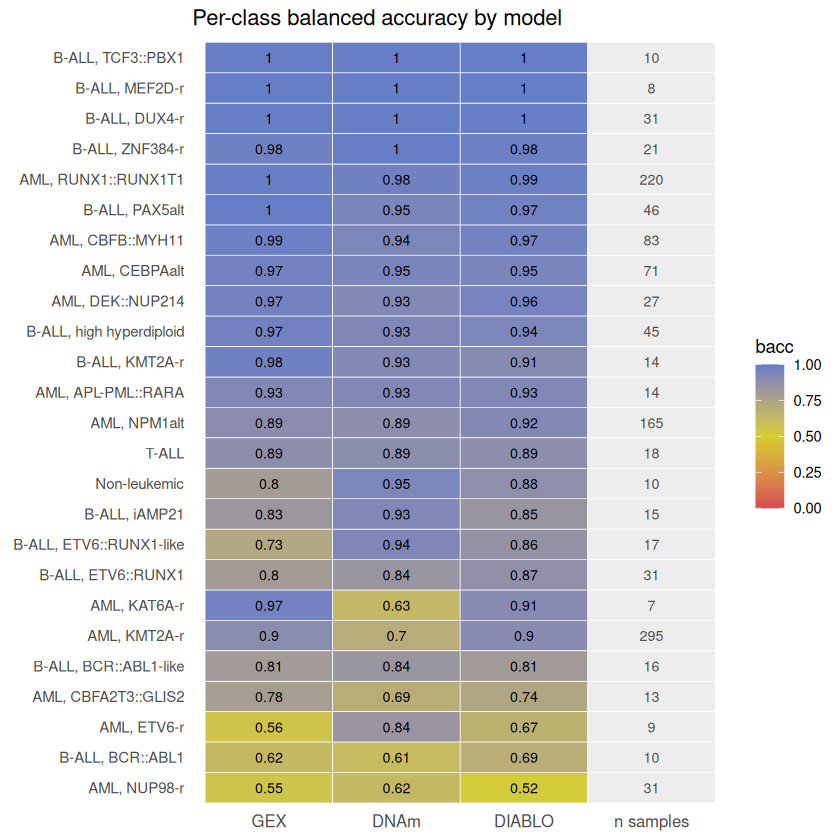

In [30]:
# Add average bacc column for sorting
bacc_wide <- bacc_wide %>%
  mutate(avg_bacc = (GEX + DNAm + DIABLO) / 3)

# Pivot to long including n_train and n_test as separate tile columns
bacc_long <- bacc_wide %>%
  pivot_longer(cols = c("GEX", "DNAm", "DIABLO"),
               names_to = "Model", values_to = "bacc")

# Create n_train and n_test rows as separate "columns"
n_df <- bacc_wide %>%
  select(Class, n_samples, avg_bacc) %>%
  pivot_longer(cols = c("n_samples"),
               names_to = "Model", values_to = "n_val") %>%
  mutate(bacc = NA)

# Combine
bacc_plot_df <- bind_rows(
  bacc_long %>% mutate(n_val = NA),
  n_df
) %>%
  mutate(Model = factor(Model,
                        levels = c("GEX", "DNAm", "DIABLO",
                                   "n_samples")))

ggplot(bacc_plot_df,
       aes(x = Model,
           y = reorder(Class, avg_bacc),
           fill = bacc)) +
  geom_tile(colour = "white") +
  # bacc values
  geom_text(data = filter(bacc_plot_df, Model %in% c("GEX","DNAm","DIABLO")),
            aes(label = round(bacc, 2)), size = 3) +
  # n_train and n_test values
  geom_text(data = filter(bacc_plot_df, Model %in% c("n_samples")),
            aes(label = n_val), size = 3, colour = "grey30") +
  scale_fill_gradient2(low       = RED,
                       mid       = YELLOW,
                       high      = BLUE,
                       midpoint  = 0.5,
                       limits    = c(0, 1),
                       na.value  = "grey93",
                       name      = "bacc") +
  scale_x_discrete(labels = c("GEX", "DNAm", "DIABLO",
                               "n samples")) +
  labs(title = "Per-class balanced accuracy by model",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x  = element_text(size = 10),
        axis.text.y  = element_text(size = 9),
        legend.position = "right",
        panel.grid   = element_blank())

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_bacc_plot.svg"),
       width = 8, height = 6, units = "in")